# Reproduce the four publication tables and verify the three locked figures

Run all cells with Python 3.13 and the packages in `analysis/requirements-confirmation.txt`. The notebook reads the frozen compact evidence, recomputes every numeric table cell, verifies the locked vector plates and their provenance, and displays their existing PNG renders. The publication figures remain read-only during this verification run.


In [1]:
from pathlib import Path
import sys, json, time, resource, subprocess
from IPython.display import display, Markdown, Image
started = time.monotonic()
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis/publication_tables.py').exists())
sys.path.insert(0, str(ROOT / 'analysis'))
from reproduce_confirmation import reproduce
from publication_tables import reproduce_tables
computed = reproduce()
publication = reproduce_tables()
tables_elapsed = time.monotonic() - started
assert tables_elapsed < 5, tables_elapsed
(ROOT / 'evidence/results/publication_table_verification_s2.json').write_text(json.dumps(publication, ensure_ascii=False, indent=2) + '\n')
print(json.dumps({'table_reproduction_seconds': tables_elapsed, 'numeric_cells_checked': publication['numeric_cells_checked'], 'all_numeric_cells_match': publication['all_numeric_cells_match'], 'mismatch_count': len(publication['mismatches']), 'attempts_total': computed['attempts_total']}))


{"table_reproduction_seconds": 0.812479916960001, "numeric_cells_checked": 158, "all_numeric_cells_match": true, "mismatch_count": 0, "attempts_total": 162506}


## Table 1. Persistent issue difficulty


In [2]:
rows = publication['tables'][0]
display(Markdown('\n'.join('| ' + ' | '.join(row) + ' |' for row in rows)))
print(json.dumps({'table': 1, 'numeric_cell_mismatches': [r for r in publication['mismatches'] if r['table'] == 1]}, ensure_ascii=False))


| Model and scaffold | Trajectories | Issues | Base $p$ | Retry $q$ | Ratio $q/p$ | 95% CI |
| :-- | --: | --: | --: | --: | --: | --: |
| Qwen3.8-27B, OpenHands | 15,168 | 5,056 | 0.594 | 0.273 | 0.459 | 0.442-0.476 |
| Qwen3-Coder-480B-A35B, OpenHands | 67,074 | 6,282 | 0.476 | 0.096 | 0.203 | 0.194-0.211 |
| Gemma 4 31B IT QAT, competition | 228 | 76 | 0.298 | 0.131 | 0.440 | 0.294-0.592 |
| Llama 3 8B, SWE-agent | 4,053 | 526 | 0.074 | 0.036 | 0.489 | 0.418-0.558 |
| Llama 3 70B, SWE-agent | 74,792 | 3,504 | 0.101 | 0.040 | 0.391 | 0.371-0.411 |
| Llama 3 405B, SWE-agent | 1,191 | 100 | 0.243 | 0.129 | 0.529 | 0.449-0.609 |

{"table": 1, "numeric_cell_mismatches": []}


## Table 2. Paired queue scheduling


In [3]:
rows = publication['tables'][1]
display(Markdown('\n'.join('| ' + ' | '.join(row) + ' |' for row in rows)))
print(json.dumps({'table': 2, 'numeric_cell_mismatches': [r for r in publication['mismatches'] if r['table'] == 2]}, ensure_ascii=False))


| Corpus and budget | Plain breadth | Ranked breadth | Deferred control | Adaptive | Ordering gain | Crossing gain | Total gain vs plain |
| :-- | --: | --: | --: | --: | --: | --: | --: |
| Qwen3.8-27B, 30% | 1314.0 | 1418.4 | 1418.4 | 1449.3 | 0.0 [0.0, 0.0] | +30.8 [5.2, 56.8] | +135.3 [90.2, 181.8] |
| Qwen3.8-27B, 40% | 1577.2 | 1641.8 | 1642.0 | 1660.6 | +0.2 [0.0, 4.8] | +18.6 [−1.8, 36.0] | +83.3 [55.2, 110.0] |
| Qwen3.8-27B, 50% | 1744.3 | 1752.5 | 1802.2 | 1804.8 | +49.7 [27.2, 72.0] | +2.6 [−4.8, 16.8] | +60.6 [37.0, 82.0] |
| Qwen3-Coder-480B, 20% | 907.1 | 976.2 | 976.2 | 976.2 | 0.0 [0.0, 0.0] | 0.0 [0.0, 0.0] | +69.1 [38.0, 105.0] |
| Qwen3-Coder-480B, 30% | 1361.5 | 1429.5 | 1429.5 | 1429.5 | 0.0 [0.0, 0.0] | 0.0 [0.0, 0.0] | +68.1 [46.0, 93.0] |
| Qwen3-Coder-480B, 50% | 1654.6 | 1661.9 | 1661.2 | 1661.2 | −0.7 [−4.0, 3.0] | 0.0 [0.0, 0.0] | +6.5 [−4.0, 16.0] |

{"table": 2, "numeric_cell_mismatches": []}


## Table 3. Gemma sandbox and trajectory audit


In [4]:
rows = publication['tables'][2]
display(Markdown('\n'.join('| ' + ' | '.join(row) + ' |' for row in rows)))
print(json.dumps({'table': 3, 'numeric_cell_mismatches': [r for r in publication['mismatches'] if r['table'] == 3]}, ensure_ascii=False))


| Audit dimension / failure modality | Exposed wins (of 68) | Exposed losses (of 160) | Total events / tasks | Restart rate $q$ | 95% CI / exact test |
| :-- | --: | --: | --: | --: | :-- |
| Reference patch passes in default sandbox | n/a | n/a | 76 / 129 tasks | 0.131 | 0.080-0.193 |
| Reference fails: missing `inline_snapshot` / `dirty_equals` | n/a | n/a | 23 / 129 tasks | n/a | Unsolvable in default wheels |
| Reference fails: per-task env / async / cert calibration | n/a | n/a | 30 / 129 tasks | n/a | Excluded from denominator |
| Any `edit_file` tool error | 21 | 76 | 97 attempts | 0.164 | 0.086-0.267 |
| Schema-rejected `edit_file` (missing `old_string`) | 12 | 38 | 1,988 calls | 0.197 | 0.081-0.353 |
| Non-schema `edit_file` string mismatch | 13 | 53 | 66 attempts | 0.123 | 0.045-0.216 |
| Wall-clock timeout at 600s cap | 0 | 28 | 28 attempts | 0.196 | 0.068-0.370 |
| Context-window overflow (32K limit) | 0 | 12 | 12 attempts | 0.083 | 0.000-0.300 |
| Early action loop flag | 4 | 15 | 19 attempts | 0.300 | 0.100-0.563 |
| Exact $\ge 5$ consecutive identical tool calls | 0 | 9 | 13 paired tasks | n/a | Sign test $p = 0.00391$ |

{"table": 3, "numeric_cell_mismatches": []}


## Table 4. Runtime stopping monitor selection


In [5]:
rows = publication['tables'][3]
display(Markdown('\n'.join('| ' + ' | '.join(row) + ' |' for row in rows)))
print(json.dumps({'table': 4, 'numeric_cell_mismatches': [r for r in publication['mismatches'] if r['table'] == 4]}, ensure_ascii=False))


| System | AUC-selected gain | Value-selected gain | Selected gate AUC | Stops / lost $Y$ | Saved calls $R$ | Loss rate $Y/R$ vs $\lambda$ |
| :-- | --: | --: | --: | --: | --: | --: |
| SWE-agent + GPT-4o | +1.03 | +2.91 | 0.557 | 39 / 7.0 | 1,640 | 0.0043 < 0.0071 |
| Agentless 1.5 + GPT-4o | −0.71 | +2.84 | 0.741 | 38 / 5.0 | 377 | 0.0133 < 0.0265 |
| OpenHands + Claude 3.5 Sonnet | +0.88 | +3.31 | 0.493 | 40 / 20.0 | 1,164 | 0.0172 < 0.0218 |
| Mini SWE Agent + Claude 4.5 Haiku | −2.41 | +3.52 | 0.533 | 35 / 20.0 | 2,558 | 0.0078 < 0.0099 |
| **Four-system sum (pooled CI)** | −1.22 | +12.57 | 0.581 mean | 152 / 52.0 | 5,739 | +13.8 over AUC |

{"table": 4, "numeric_cell_mismatches": []}


## Verify the three locked vector figures

The figure sidecar binds the frozen results, collision checks, pixel checks, and vector PDF sizes. This execution checks the current PDF and PNG hashes against the manuscript build receipt and displays the locked PNG renders. Full figure regeneration and scheduling draw generation are separate builds.


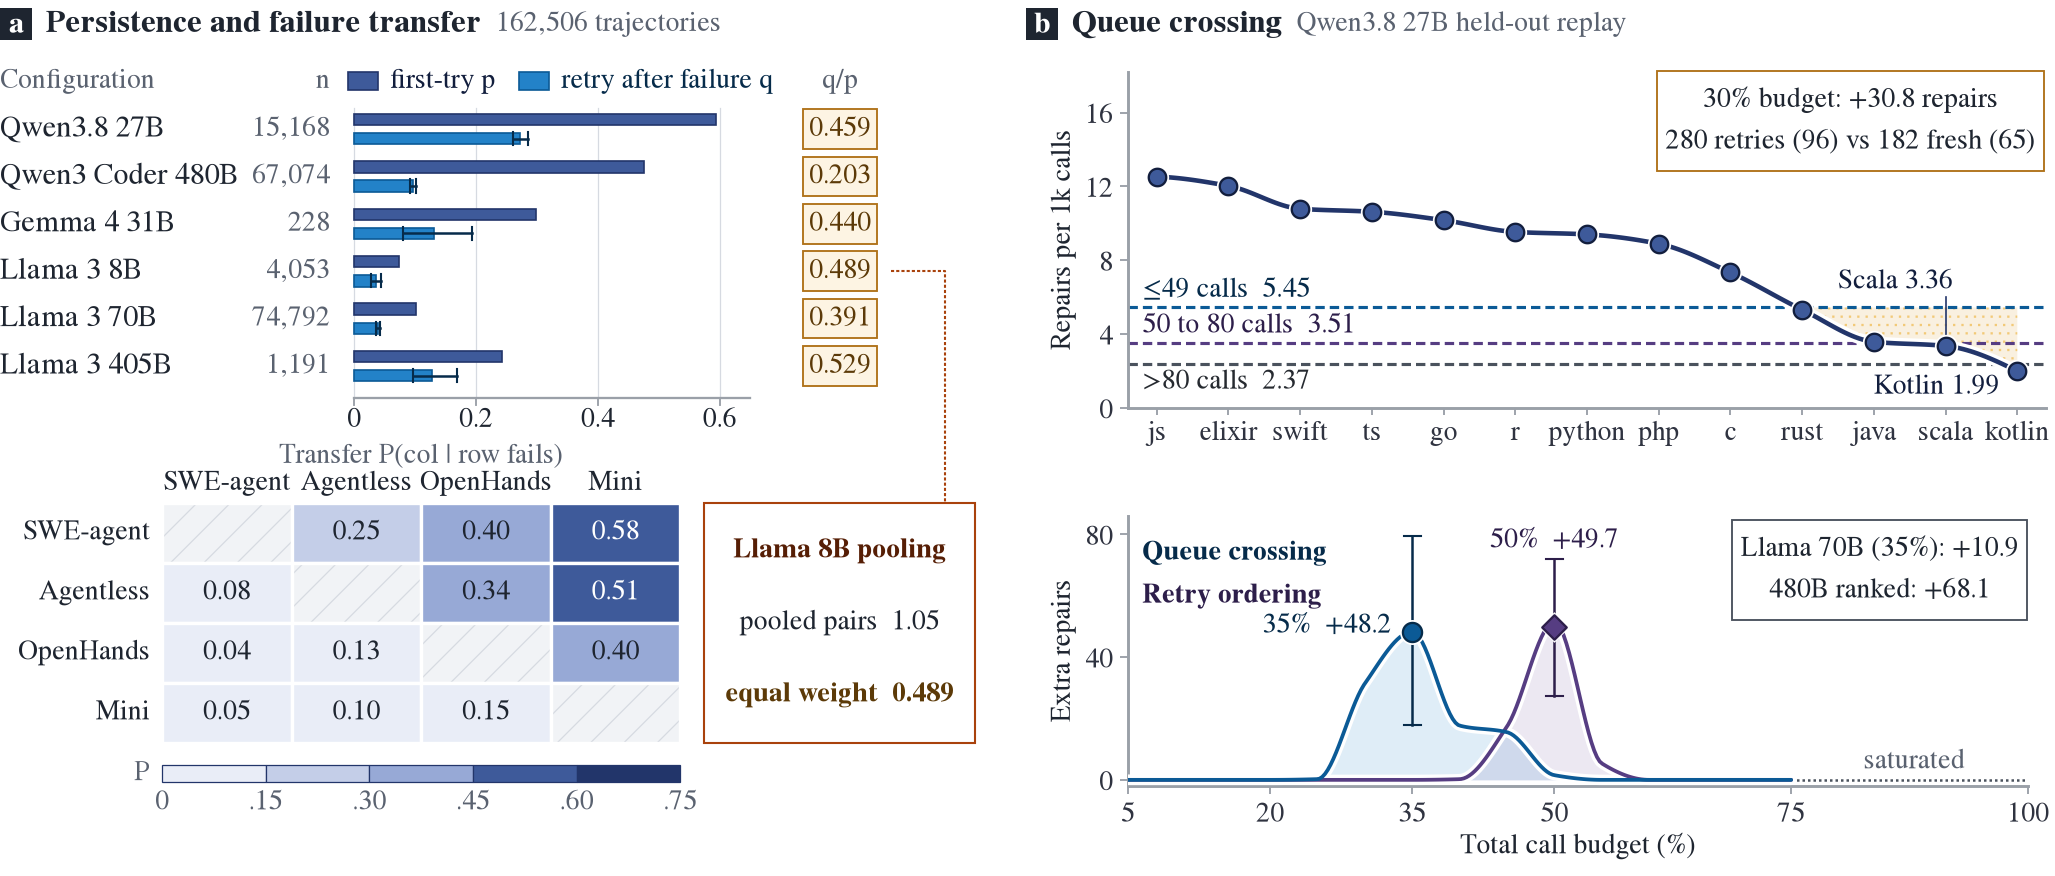

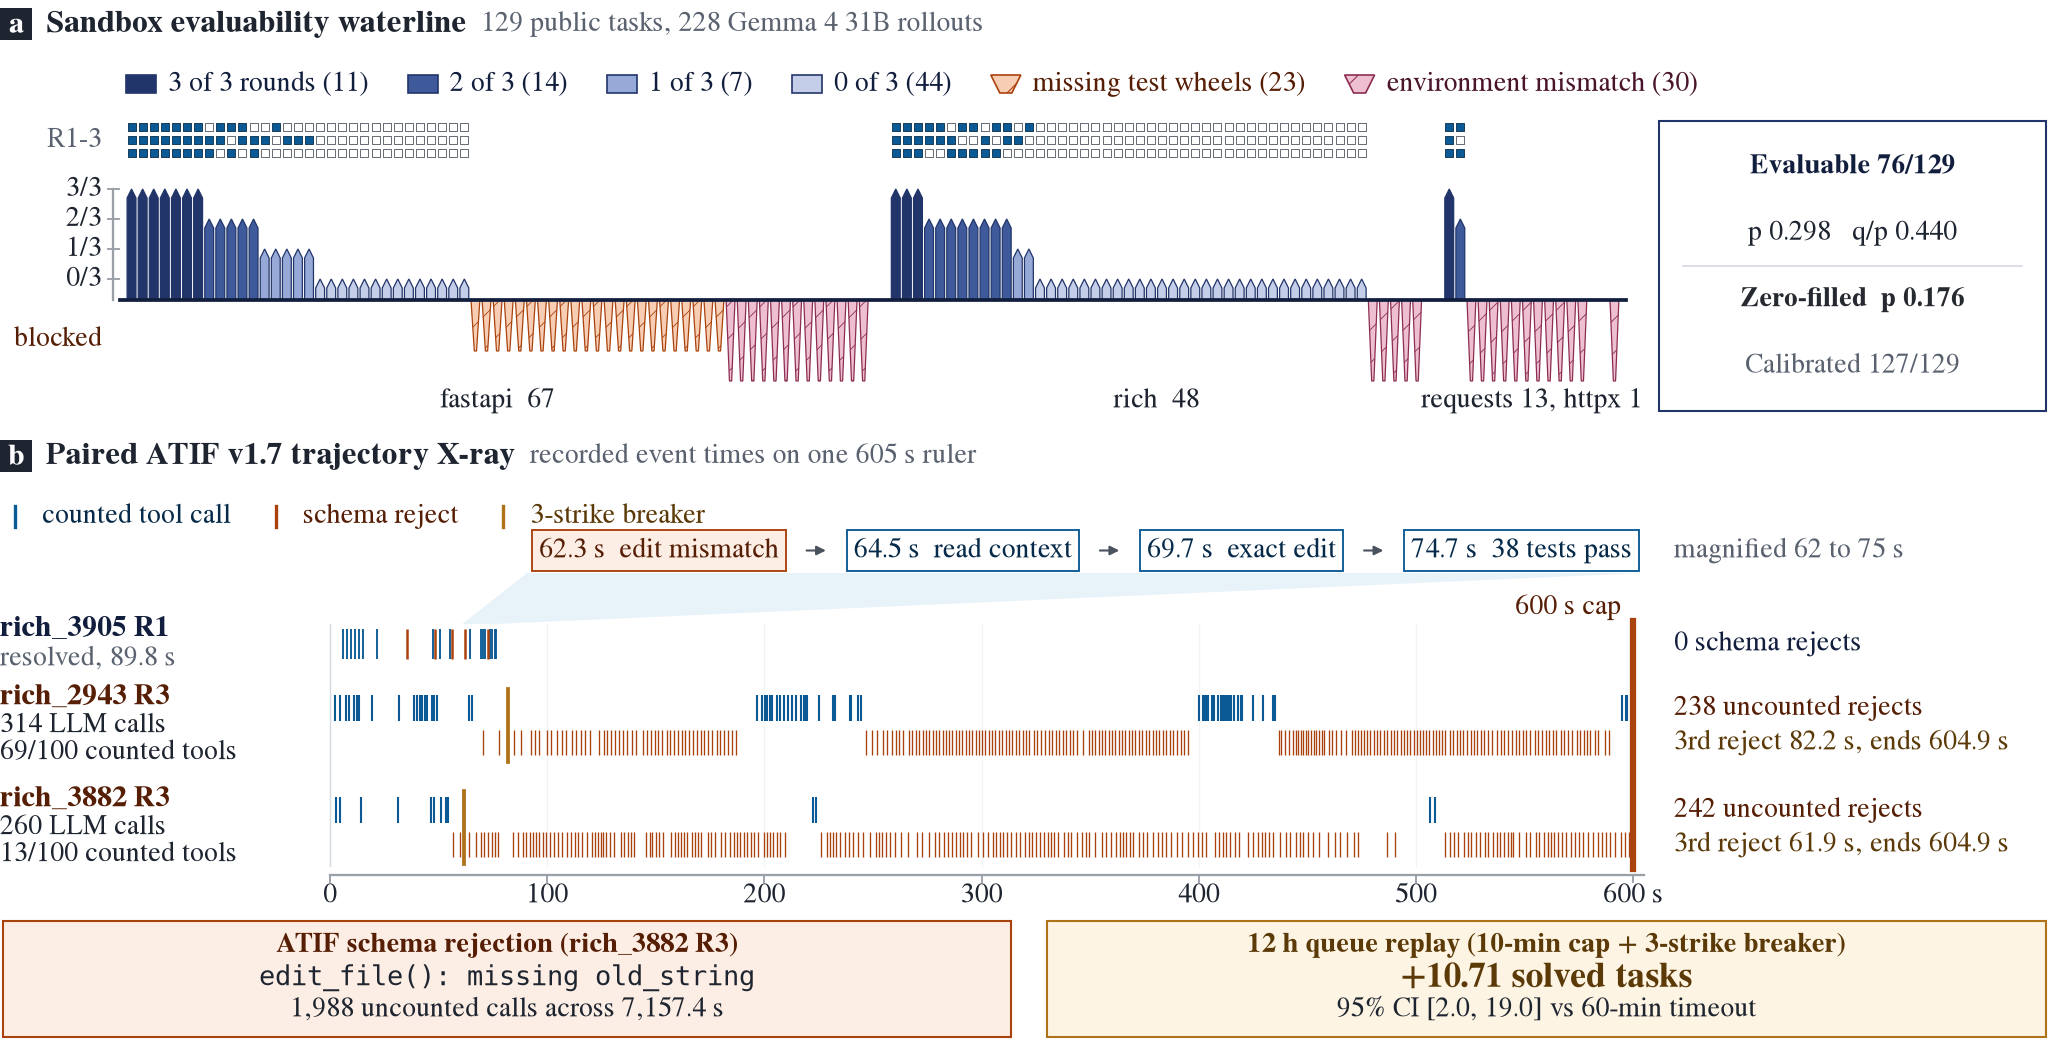

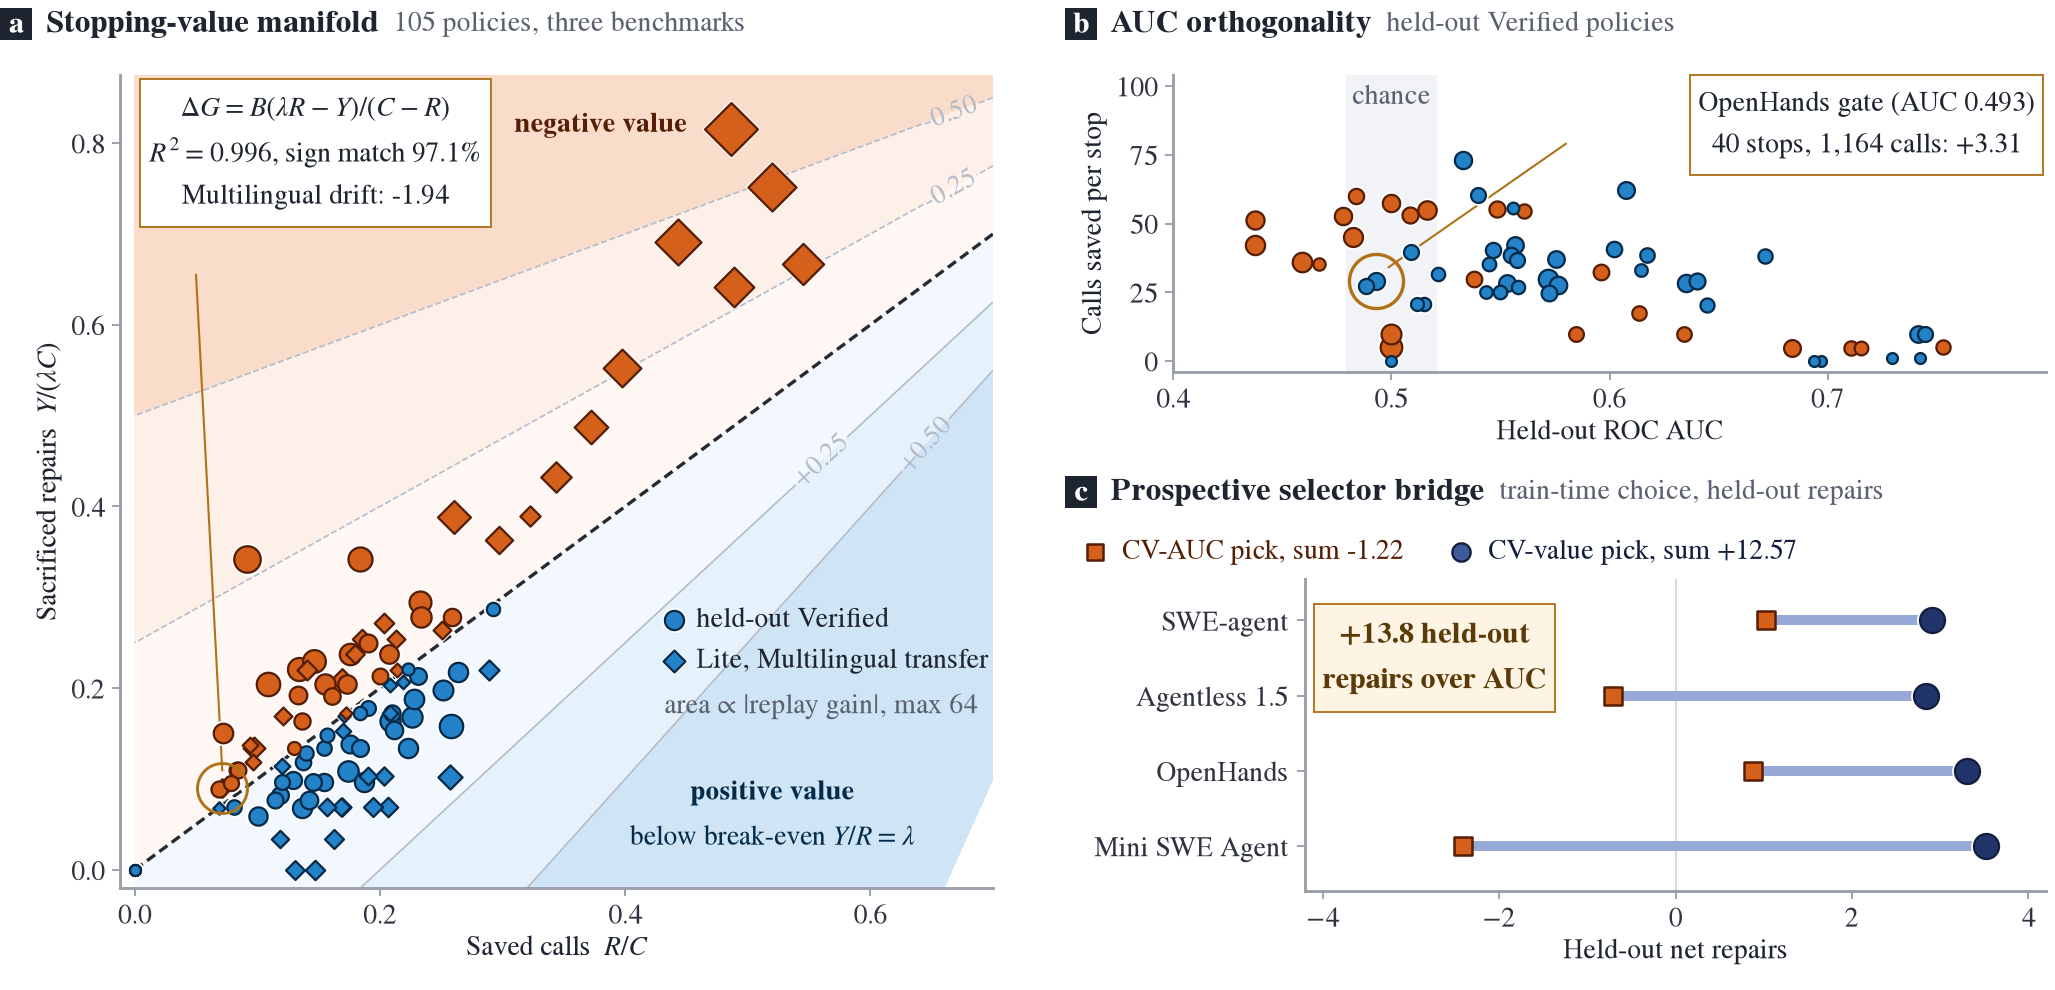

{
  "figure_verification_returncode": 0,
  "figure_seconds": 0.008733834140002728,
  "checks": {
    "fig1_persistence_and_queue_crossing": {
      "hit_count": 0,
      "green_px": 0,
      "pdf_bytes": 51939
    },
    "fig2_gemma_xray_and_sandbox_waterline": {
      "hit_count": 0,
      "green_px": 0,
      "pdf_bytes": 47295
    },
    "fig3_stopping_value_manifold": {
      "hit_count": 0,
      "green_px": 0,
      "pdf_bytes": 152925
    }
  },
  "sha256": {
    "figures/fig1_persistence_and_queue_crossing.pdf": "972847eefaa4f995d8b706c217b6ec3669ba76ba1965d5fef67a66e6b79a08e1",
    "figures/fig1_persistence_and_queue_crossing.png": "4828d932ff33bf20e8ba1f56ddbf4da7268a036fecc56fc8fe0d5b846af14bac",
    "figures/fig2_gemma_xray_and_sandbox_waterline.pdf": "ee4ce2303bc1303b39fde5d6603f7b2e458fb2bbc0f2a0445c9979cee4973d2d",
    "figures/fig2_gemma_xray_and_sandbox_waterline.png": "2d7d13dc7a709f9e514e48c1cb3326603308c4b9f22c063efe96676819e199ef",
    "figures/fig3_stopping_value_

In [6]:
import hashlib
figure_started = time.monotonic()
figure_receipt = json.loads((ROOT / 'paper/figures/publication_figures_provenance.json').read_text())
build_receipt = json.loads((ROOT / 'evidence/results/latex_sync_s2.json').read_text())
expected = ('fig1_persistence_and_queue_crossing', 'fig2_gemma_xray_and_sandbox_waterline', 'fig3_stopping_value_manifold')
figure_checks = {name: {k: row[k] for k in ('hit_count', 'green_px', 'pdf_bytes') if k in row} for name, row in figure_receipt['checks'].items()}
figure_hashes = {}
for name in expected:
    pdf = ROOT / 'paper/figures' / (name + '.pdf')
    assert pdf.exists() and pdf.stat().st_size == figure_receipt['checks'][name]['pdf_bytes']
    assert figure_checks[name]['hit_count'] == 0 and figure_checks[name]['green_px'] == 0
    for extension in ('.pdf', '.png'):
        path = ROOT / 'paper/figures' / (name + extension)
        key = str(path.relative_to(ROOT / 'paper'))
        figure_hashes[key] = hashlib.sha256(path.read_bytes()).hexdigest()
        assert figure_hashes[key] == build_receipt['locked_figure_sha256'][key]
    display(Image(filename=str(ROOT / 'paper/figures' / (name + '.png')), width=1000))
figure_returncode = 0
print(json.dumps({'figure_verification_returncode': figure_returncode, 'figure_seconds': time.monotonic() - figure_started, 'checks': figure_checks, 'sha256': figure_hashes, 'source_figures_read_only': True}, indent=2))


## Execution receipt


In [7]:
elapsed = time.monotonic() - started
rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
rss_bytes = rss if sys.platform == 'darwin' else rss * 1024
assert elapsed < 60, elapsed
assert rss_bytes < 4 * 1024**3, rss_bytes
print(json.dumps({'elapsed_seconds': elapsed, 'table_seconds': tables_elapsed, 'kernel_peak_rss_bytes': rss_bytes, 'model_configurations': computed['model_configurations'], 'attempts_total': computed['attempts_total'], 'numeric_cells_checked': publication['numeric_cells_checked'], 'all_numeric_cells_match': publication['all_numeric_cells_match'], 'mismatch_count': len(publication['mismatches']), 'figure_returncode': figure_returncode, 'execution_checks': 'passed', 'publication_checks': 'passed' if publication['all_numeric_cells_match'] and figure_returncode == 0 else 'needs_source_reconciliation'}))


{"elapsed_seconds": 0.8425104999914765, "table_seconds": 0.812479916960001, "kernel_peak_rss_bytes": 202620928, "model_configurations": 6, "attempts_total": 162506, "numeric_cells_checked": 158, "all_numeric_cells_match": true, "mismatch_count": 0, "figure_returncode": 0, "execution_checks": "passed", "publication_checks": "passed"}
